# Flood segmentation: graph cut vs U-Net vs SegFormer-B0

**Task.** Binary semantic segmentation of flooded areas (flood = water, flooded road, flooded building) in UAV, oblique aerial, and street-level imagery.

**Research question.** Are hand-designed colour and region cues enough to map floodwater, or does it take learned features and global context? How much does a from-scratch model suffer on limited data compared with a pretrained one, and how far do models trained on top-down UAV images transfer to street-level photos?

| Slot | Method | Code |
|---|---|---|
| A. Classical | Graph cut: colour, two-scale texture, and row-position GMM unaries, contrast-sensitive Potts, our own Boykov-Kolmogorov max-flow | `src/methods/classical.py` |
| B. From scratch | U-Net written in PyTorch, random init | `src/methods/scratch.py` |
| C. Pretrained | SegFormer-B0 (MiT-B0 ImageNet encoder), fine-tuned | `src/methods/pretrained.py` |

All three share the same fixed splits (`splits/`), are trained in two configurations (FloodNet only, and mixed = FloodNet + Kaggle aerial + Roadway street-level), the same metrics (`src/eval/metrics.py`), and the same `load`/`predict` interface.

## 0. Setup
In Colab this clones the repo, installs requirements, and downloads the trained checkpoints from the GitHub release. Set `TRAIN = True` to retrain every model instead; `TRAIN_ABLATION = True` retrains the data-size runs.

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules
TRAIN = False
TRAIN_ABLATION = False

if IN_COLAB:
    if not os.path.exists("/content/ccs-250-final-project"):
        !git clone -q https://github.com/athenavillarin/ccs-250-final-project.git /content/ccs-250-final-project
    %cd /content/ccs-250-final-project
    !pip install -q -r requirements.txt
    os.environ["FLOOD_DATA_DIR"] = "/content/data"
    os.environ["FLOOD_CHECKPOINT_DIR"] = "/content/checkpoints"
elif os.path.basename(os.getcwd()) == "notebooks":
    %cd ..
sys.path.insert(0, os.getcwd())
if not TRAIN:
    !python scripts/download_checkpoints.py {"" if TRAIN_ABLATION else "--all"}

import numpy as np
import pandas as pd
import torch
from IPython.display import Image as Show, display

from src.utils.paths import CHECKPOINT_DIR, DATA_DIR, RESULTS_DIR
from src.utils.seed import seed_everything

seed_everything()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

C:\Users\ganim\Documents\school\4.1\Computer Vision\Final Project\ccs-250-final-project


device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Data
FloodNet Supervised v1.0 (UAV, official train/val/test), the Kaggle Flood Area Segmentation set (oblique aerial), and the Roadway Flooding set (street level, Sazara et al. 2019). The two extra sets get fixed 70/15/15 splits. Images are stored at 1024 px on the long side at most. Regenerating the splits must leave `splits/` unchanged.

In [2]:
if not all((DATA_DIR / d).exists() for d in ("floodnet/test", "kaggle", "roadway")):
    !python scripts/download_data.py
!python scripts/make_splits.py
!git status --short splits

train: 1445
val: 450
test: 448
train_25: 361
train_50: 722


In [3]:
from src.data.dataset import load_pair, read_split
from src.utils.viz import overlay, plt

stats = []
for split in ("train", "val", "test", "kaggle_train", "kaggle_val", "kaggle_test", "roadway_train", "roadway_val", "roadway_test"):
    ids = read_split(split)
    flood = np.mean([load_pair(split, i)[1].mean() for i in ids[:: max(1, len(ids) // 100)]])
    stats.append({"split": split, "images": len(ids), "flood_pixels_%": round(100 * flood, 1)})
display(pd.DataFrame(stats))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (split, i) in zip(axes, [("train", 0), ("test", 7), ("kaggle_train", 3), ("roadway_train", 5)]):
    image, mask = load_pair(split, read_split(split)[i])
    ax.imshow(overlay(image, mask))
    ax.set_title(f"{split}: flood mask in blue")
    ax.axis("off")
plt.show()

,split,images,flood_pixels_%
0,train,1445,17.2
1,val,450,15.5
2,test,448,13.7
3,kaggle,290,39.3


C:\Users\ganim\AppData\Local\Temp\ipykernel_18080\3900588579.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 2. Classical: graph cut
### 2.1 Max-flow correctness
Our Boykov-Kolmogorov solver is checked on random grids against the max-flow value from SciPy (used only as a test oracle) and against the max-flow/min-cut theorem.

In [4]:
!python -m pytest -q tests

........................................................................ [ 72%]
............................                                             [100%]
100 passed in 7.37s


### 2.2 Synthetic sanity check
A winding river and a pond with known ground truth, rendered with heavy Gaussian noise. Pixel-wise labeling (lambda = 0) is compared with the graph cut.

 sigma  lambda   miou  iou_flood  dice  pixel_acc
    15       0 70.999     61.472 0.761     85.142
    15       1 76.193     67.772 0.808     88.375
    15       2 79.254     71.640 0.835     90.139
    15       5 84.446     78.421 0.879     92.922
    15      10 88.329     83.627 0.911     94.861
    15      20 91.154     87.497 0.933     96.193
    30       0 70.999     61.472 0.761     85.142
    30       1 86.056     80.580 0.892     93.734
    30       2 92.723     89.683 0.946     96.903
    30       5 96.775     95.381 0.976     98.671
    30      10 97.613     96.573 0.983     99.023
    30      20 97.711     96.710 0.983     99.066
    60       0 70.999     61.472 0.761     85.142
    60       1 93.963     91.408 0.955     97.459
    60       2 98.042     97.184 0.986     99.202
    60       5 98.695     98.122 0.991     99.471
    60      10 98.263     97.504 0.987     99.292
    60      20 97.594     96.552 0.982     99.013


W1115 12:19:07.646000 6932 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


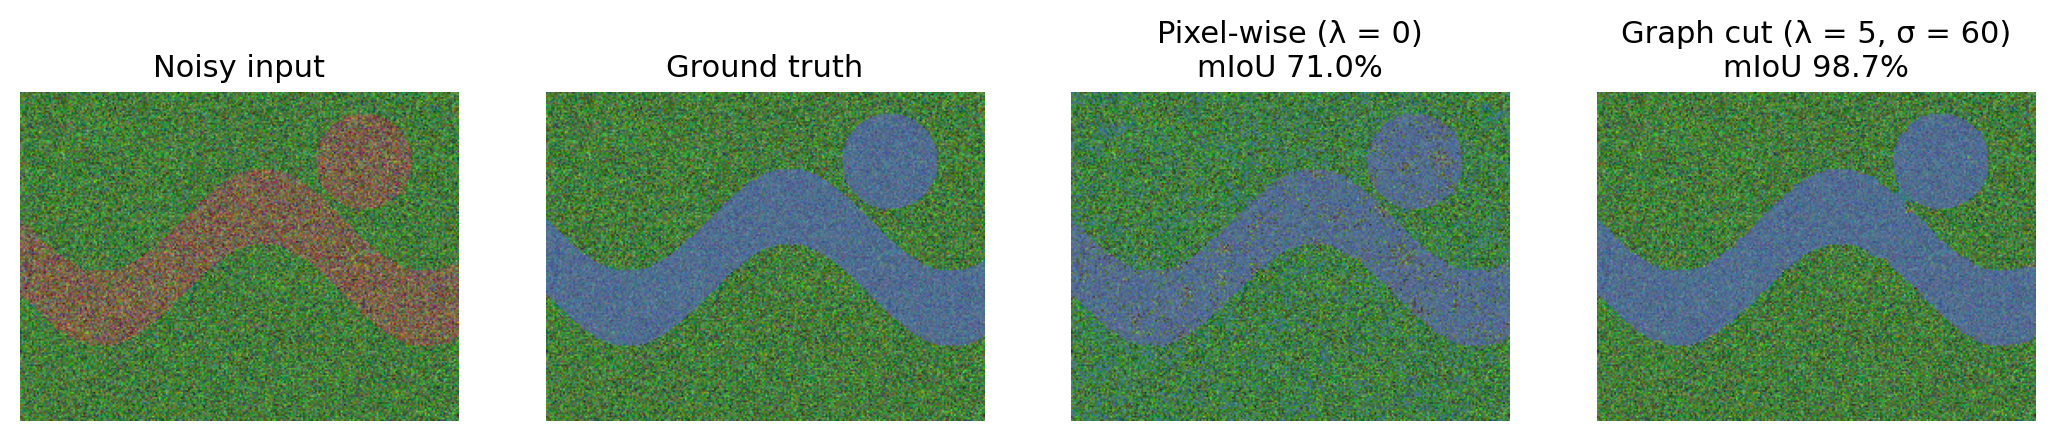

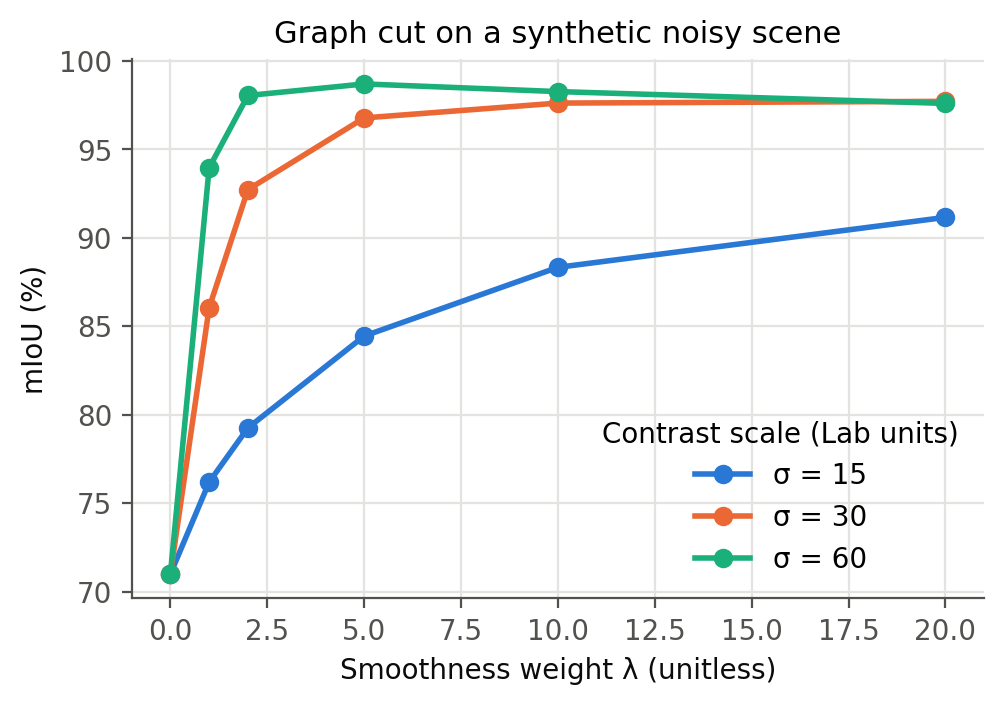

In [5]:
!python scripts/sanity_classical.py
display(Show(str(RESULTS_DIR / "sanity_classical.png")), Show(str(RESULTS_DIR / "sanity_classical_sweep.png")))

### 2.3 Fit on each training configuration, tune lambda, sigma, and bias on val
Flood and background GMMs over Lab colour, lightness std at two window sizes (calm water is smooth), and the row position (water sits low in street photos) are fit on the training split; lambda, sigma, and the flood bias are chosen on a fixed subset of the matching val split(s) only. The graph cut runs at 256 px and the mask is upsampled for evaluation.

,sigma,bias,lambda,miou,iou_flood,dice,pixel_acc
2,10,-1.0,10,65.298,43.228,0.604,88.477
10,10,-0.5,40,65.291,44.031,0.611,87.838
27,20,-0.5,20,65.291,43.714,0.608,88.083
1,10,-1.0,5,65.180,43.476,0.606,88.085
35,20,0.0,80,64.883,44.501,0.616,86.822


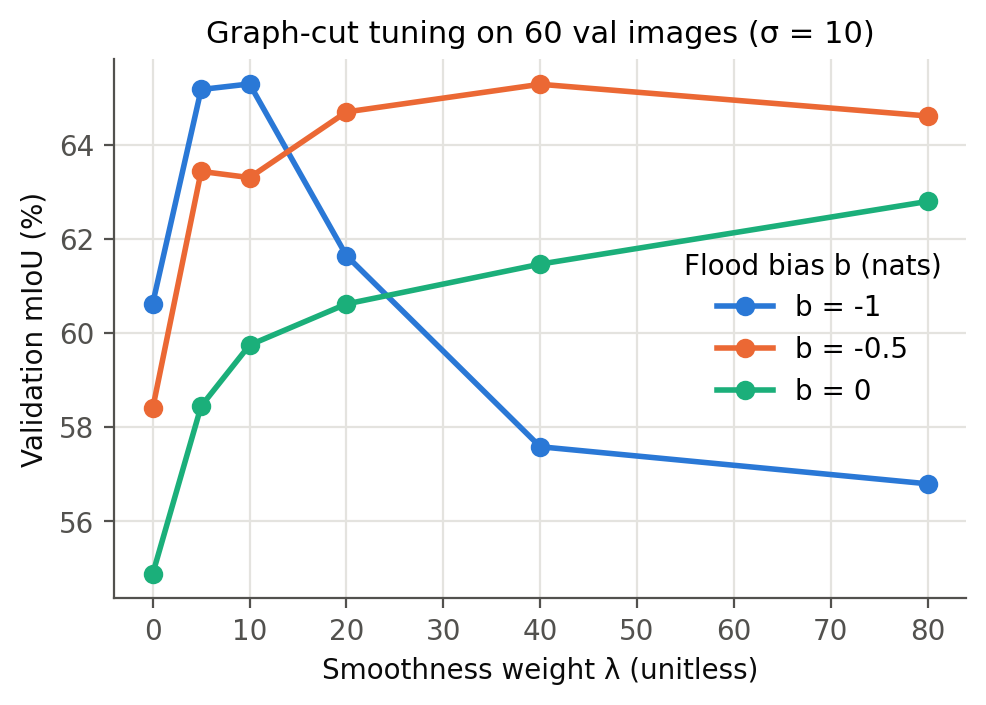

In [6]:
for split in ("train", "mixed"):
    if TRAIN or not (CHECKPOINT_DIR / f"classical_{split}.npz").exists():
        !python scripts/fit_classical.py --split {split}
    display(pd.read_csv(RESULTS_DIR / f"classical_tuning_{split}.csv").sort_values("miou", ascending=False).head(3))
display(Show(str(RESULTS_DIR / "classical_tuning_mixed.png")))

## 3. From scratch: U-Net
Four-level U-Net (batch norm, transposed-conv upsampling, bottleneck dropout), BCE + Dice loss, flips / random resized crops / colour jitter, AdamW with weight decay, cosine schedule, early stopping on val mIoU.

W1115 12:19:15.249000 18080 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


U-Net parameters: 7.76 M


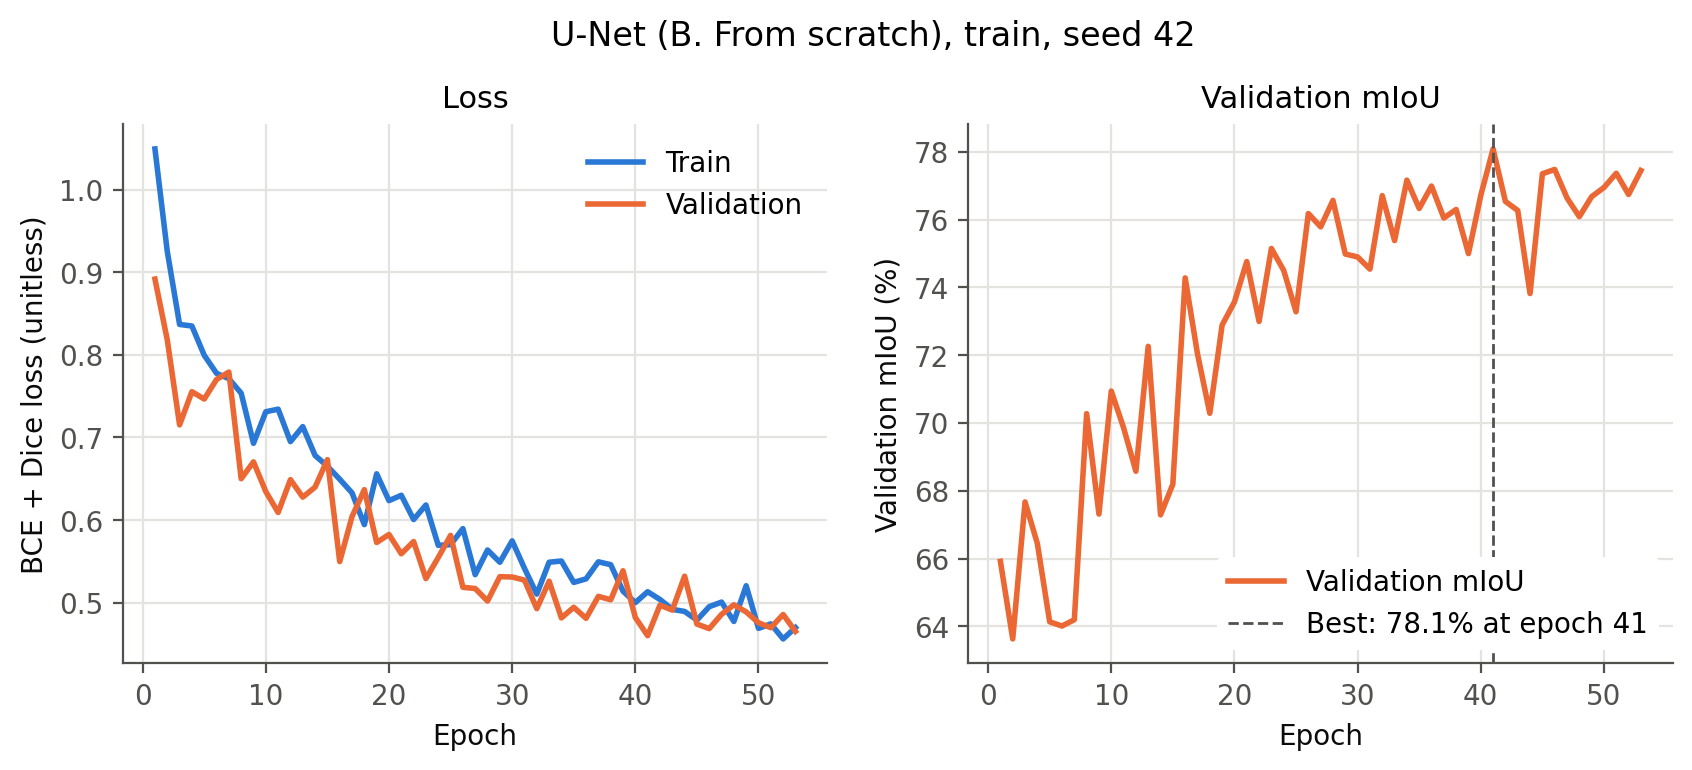

In [7]:
from src.eval.benchmark import count_params
from src.methods.scratch import UNet

print(f"U-Net parameters: {count_params(UNet()):.2f} M")
for split in ("mixed", "train"):
    if TRAIN or not (CHECKPOINT_DIR / f"scratch_{split}_s42.pt").exists():
        !python scripts/train.py --method scratch --split {split} --device {DEVICE}
display(Show(str(RESULTS_DIR / "curves_scratch_mixed_s42.png")))

## 4. Pretrained: SegFormer-B0
ImageNet-pretrained MiT-B0 encoder with a one-logit decode head, normalised with the statistics of its own image processor; logits are upsampled to the input size before thresholding. Same splits, loss, and augmentation as the U-Net.

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

SegFormer-B0 parameters: 3.71 M


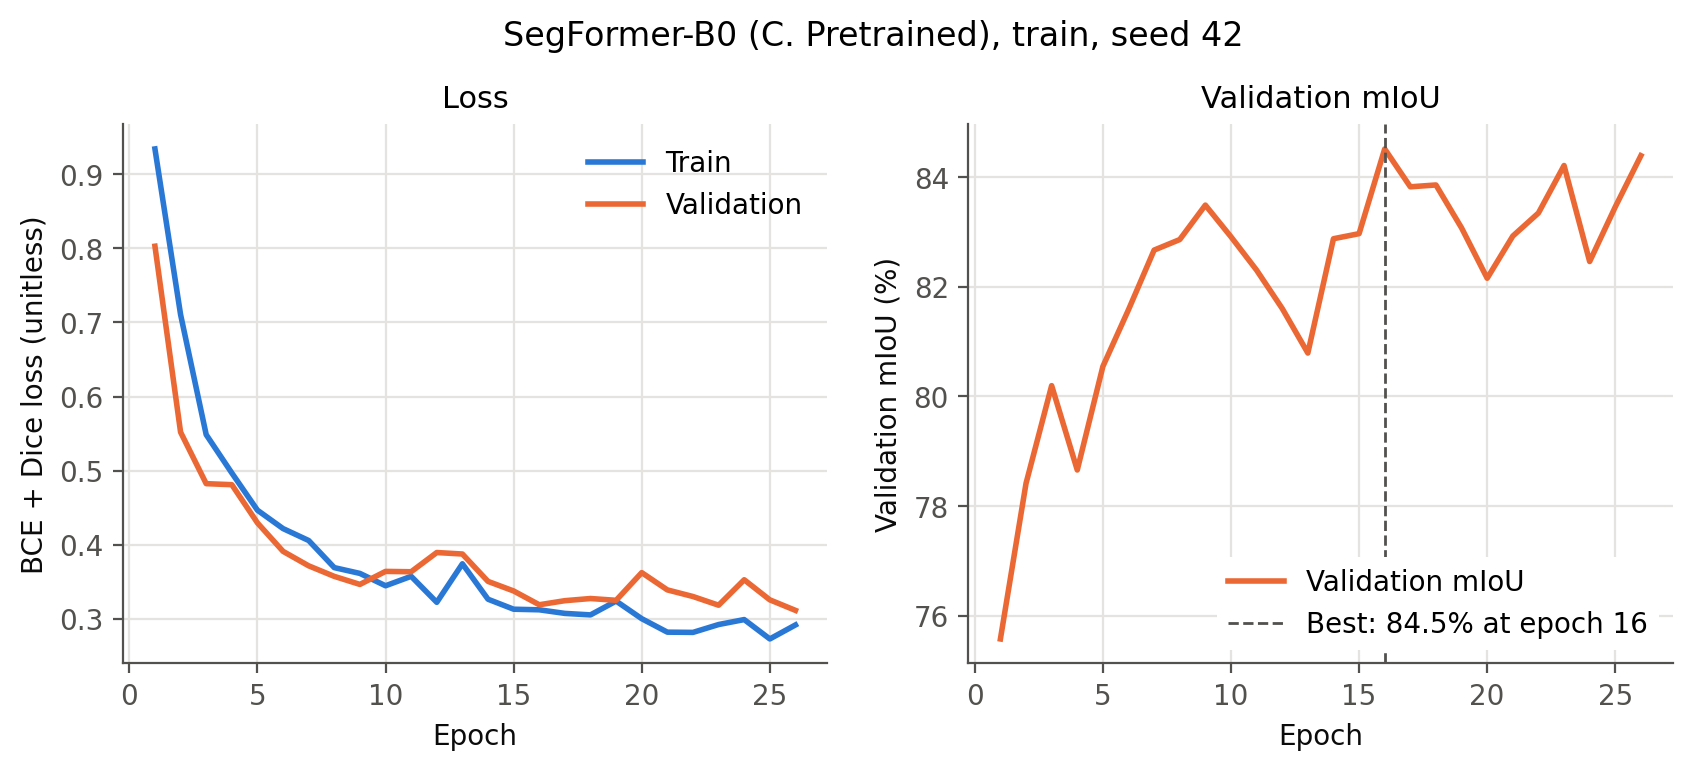

In [8]:
from src.methods.pretrained import SegFormer

print(f"SegFormer-B0 parameters: {count_params(SegFormer()):.2f} M")
for split in ("mixed", "train"):
    if TRAIN or not (CHECKPOINT_DIR / f"pretrained_{split}_s42.pt").exists():
        !python scripts/train.py --method pretrained --split {split} --device {DEVICE}
display(Show(str(RESULTS_DIR / "curves_pretrained_mixed_s42.png")))

### 4.1 Training on 25% and 50% of FloodNet train (for the ablation)

In [9]:
for method in ("scratch", "pretrained"):
    for split in ("train_50", "train_25"):
        if TRAIN_ABLATION or not (CHECKPOINT_DIR / f"{method}_{split}_s42.pt").exists():
            !python scripts/train.py --method {method} --split {split} --device {DEVICE}
display(pd.read_csv(RESULTS_DIR / "training_runs.csv"))

,method,split,seed,train_min,params_m,best_val_miou
0,classical,train,42,8.07,0.000,65.30
1,pretrained,train,42,10.90,3.714,84.51
2,scratch,train,42,26.83,7.763,78.08
3,pretrained,train_50,42,13.65,3.714,83.90
4,scratch,train_50,42,19.34,7.763,76.52
5,pretrained,train_25,42,10.44,3.714,81.85
6,scratch,train_25,42,10.33,7.763,75.03


## 5. Experiments
Predictions are cached under `data/preds/`, so this cell is fast after the first run.

In [10]:
!python scripts/run_experiments.py --device {DEVICE}

    method         name            slot   miou  iou_flood  dice  pixel_acc  runtime_ms device  params_m  train_min
 classical    Graph cut    A. Classical 65.320     43.208 0.603     88.530     398.430    CPU     0.000       8.07
   scratch        U-Net B. From scratch 77.462     62.404 0.769     93.346      19.014   CUDA     7.763      26.83
pretrained SegFormer-B0   C. Pretrained 83.328     72.032 0.837     95.278      23.232   CUDA     3.714      10.90
    method         name            slot   miou  iou_flood  dice  pixel_acc  runtime_ms device  params_m  train_min
 classical    Graph cut    A. Classical 42.449     25.431 0.405     64.389     668.970    CPU     0.000       8.07
   scratch        U-Net B. From scratch 54.478     47.880 0.648     71.328      15.179   CUDA     7.763      26.83
pretrained SegFormer-B0   C. Pretrained 51.662     41.471 0.586     69.970      21.278   CUDA     3.714      10.90
    method         name  train_pct  train_images   miou  iou_flood  dice  pixel_

W1115 12:19:23.551000 23264 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|##########| 192/192 [00:00<00:00, 27901.96it/s]

Loading weights: 100%|##########| 192/192 [00:00<00:00, 20572.39it/s]

Loading weights: 100%|##########| 192/192 [00:00<00:00, 20585.01it/s]

Loading weights: 100%|##########| 192/192 [00:00<00:00, 18995.76it/s]

per-class: 100%|##########| 448/448 [00:11<00:00, 38.53it/s]


### 5.1 Experiment 1: main comparison of the mixed models on the FloodNet test split

In [11]:
display(pd.read_csv(RESULTS_DIR / 'main_results.csv'))

,method,name,slot,miou,iou_flood,dice,pixel_acc,runtime_ms,device,params_m,train_min
0,classical,Graph cut,A. Classical,65.320,43.208,0.603,88.530,398.430,CPU,0.000,8.07
1,scratch,U-Net,B. From scratch,77.462,62.404,0.769,93.346,19.014,CUDA,7.763,26.83
2,pretrained,SegFormer-B0,C. Pretrained,83.328,72.032,0.837,95.278,23.232,CUDA,3.714,10.90


### 5.2 Experiment 2: data-size ablation

,method,name,train_pct,train_images,miou,iou_flood,dice,pixel_acc
0,scratch,U-Net,25,361,74.603,57.409,0.729,92.613
1,scratch,U-Net,50,722,76.025,59.645,0.747,93.171
2,scratch,U-Net,100,1445,77.462,62.404,0.769,93.346
3,pretrained,SegFormer-B0,25,361,81.255,68.569,0.814,94.648
4,pretrained,SegFormer-B0,50,722,83.249,71.847,0.836,95.293
5,pretrained,SegFormer-B0,100,1445,83.328,72.032,0.837,95.278


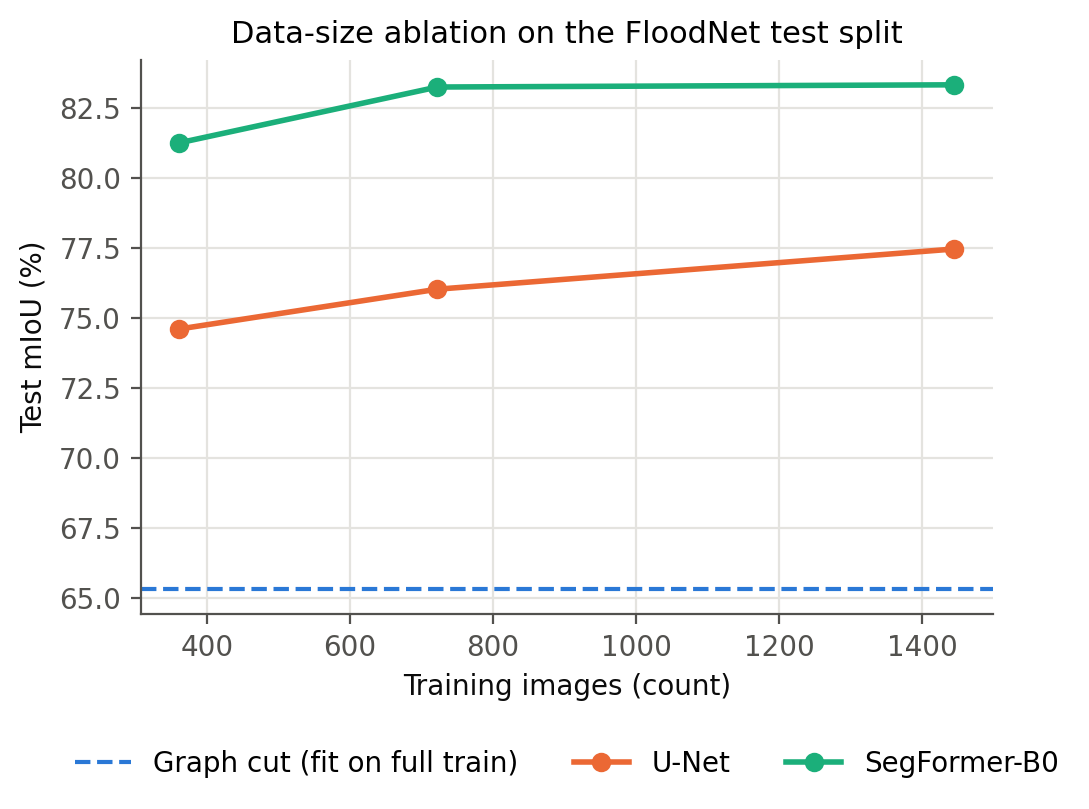

In [12]:
display(pd.read_csv(RESULTS_DIR / "ablation_data_size.csv"))
display(Show(str(RESULTS_DIR / "ablation_data_size.png")))

### 5.3 Experiment 3: efficiency (CPU vs GPU runtime, parameters, training time)

,method,name,device,runtime_ms_median,runtime_ms_p90,params_m,train_min
0,classical,Graph cut,CPU,419.569,860.561,0.000,8.07
1,scratch,U-Net,CPU,282.625,290.829,7.763,26.83
2,scratch,U-Net,CUDA,18.813,20.270,7.763,26.83
3,pretrained,SegFormer-B0,CPU,152.810,159.302,3.714,10.90
4,pretrained,SegFormer-B0,CUDA,21.316,23.964,3.714,10.90


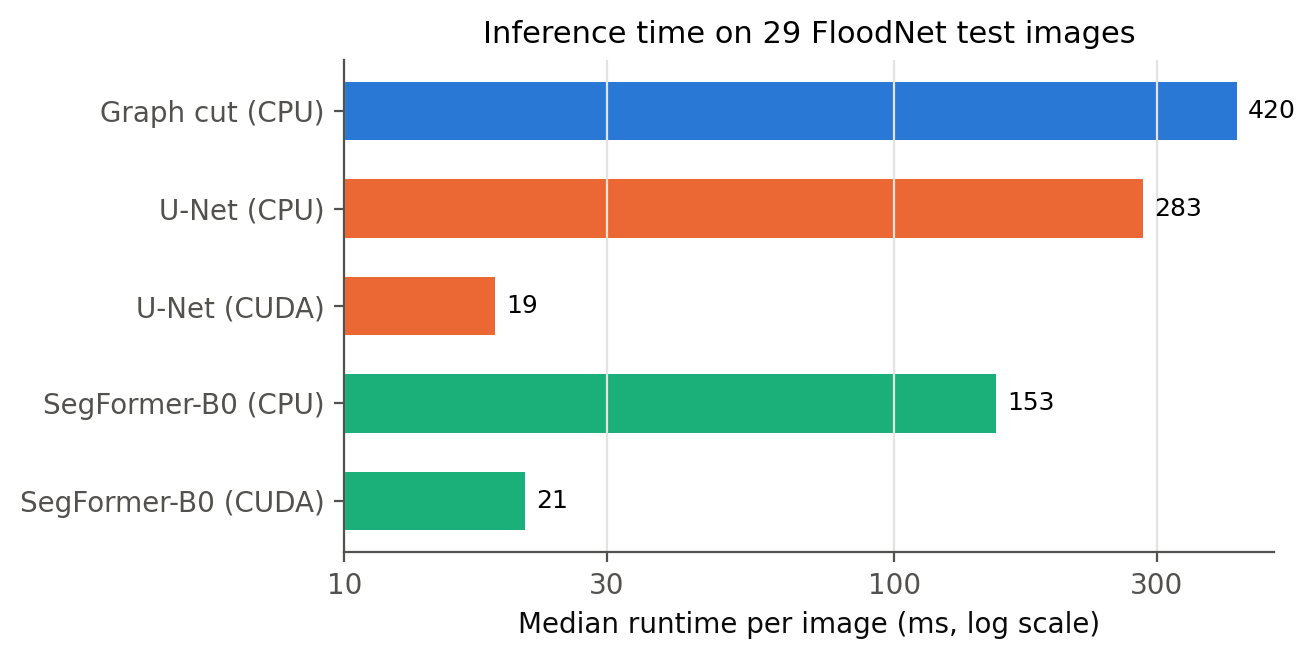

In [13]:
display(pd.read_csv(RESULTS_DIR / "efficiency.csv"))
display(Show(str(RESULTS_DIR / "efficiency_runtime.png")))

### 5.4 Experiment 4: domain shift
Each method trained on FloodNet only vs on the mixed data, scored on the held-out FloodNet (UAV), Kaggle (aerial), and Roadway (street-level) test splits, plus `data/local` when it has masks. The overlays show the same images for every model.

,method,name,slot,miou,iou_flood,dice,pixel_acc,runtime_ms,device,params_m,train_min
0,classical,Graph cut,A. Classical,42.449,25.431,0.405,64.389,668.970,CPU,0.000,8.07
1,scratch,U-Net,B. From scratch,54.478,47.880,0.648,71.328,15.179,CUDA,7.763,26.83
2,pretrained,SegFormer-B0,C. Pretrained,51.662,41.471,0.586,69.970,21.278,CUDA,3.714,10.90


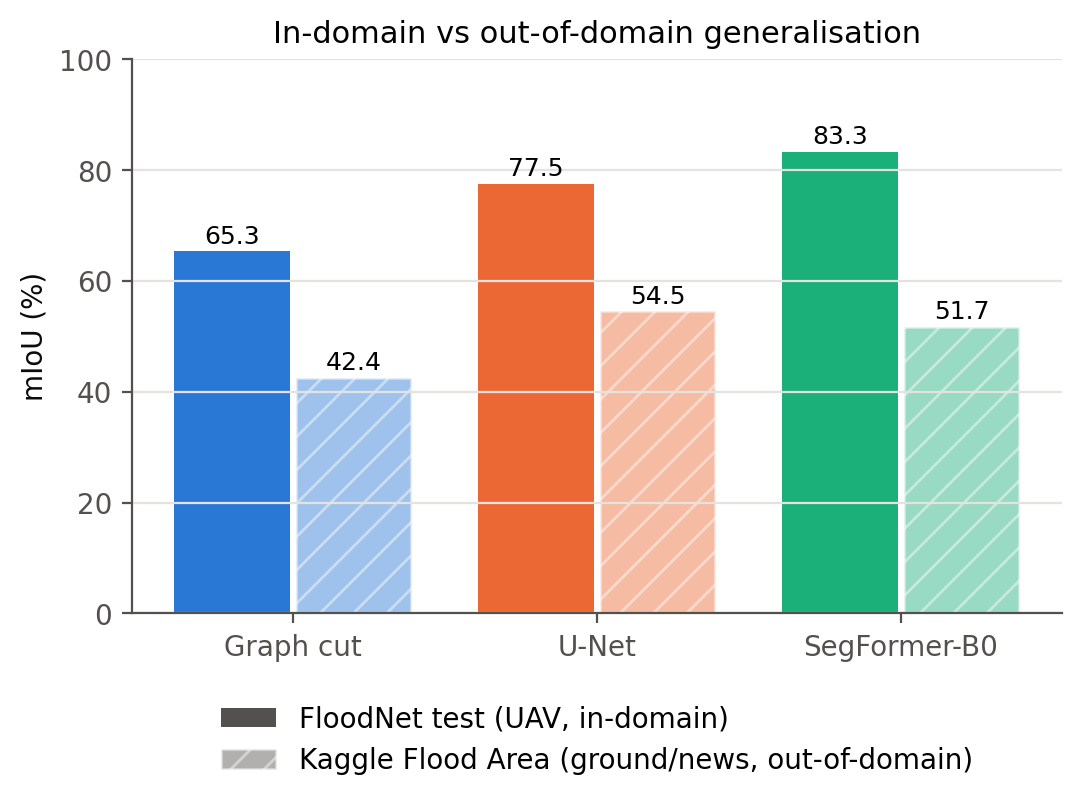

In [14]:
domain = pd.read_csv(RESULTS_DIR / "domain_shift.csv")
display(domain.pivot_table(index=["method", "train"], columns="test", values="miou").round(1))
display(Show(str(RESULTS_DIR / "domain_shift.png")), Show(str(RESULTS_DIR / "domain_examples.png")))

### 5.5 Experiment 5: failure analysis
Share of each original FloodNet class predicted as flood (high is good for flood classes, low for the others), then the hardest and easiest flooded test images.

method,classical,pretrained,scratch
class,,,
background,61.3,47.1,52.8
building-flooded,10.3,77.6,82.2
building-non-flooded,24.7,6.4,11.6
grass,4.8,1.9,2.3
pool,2.8,12.0,19.8
road-flooded,45.5,82.8,77.9
road-non-flooded,17.9,0.3,5.1
tree,1.0,2.7,2.3
vehicle,6.0,11.4,22.2


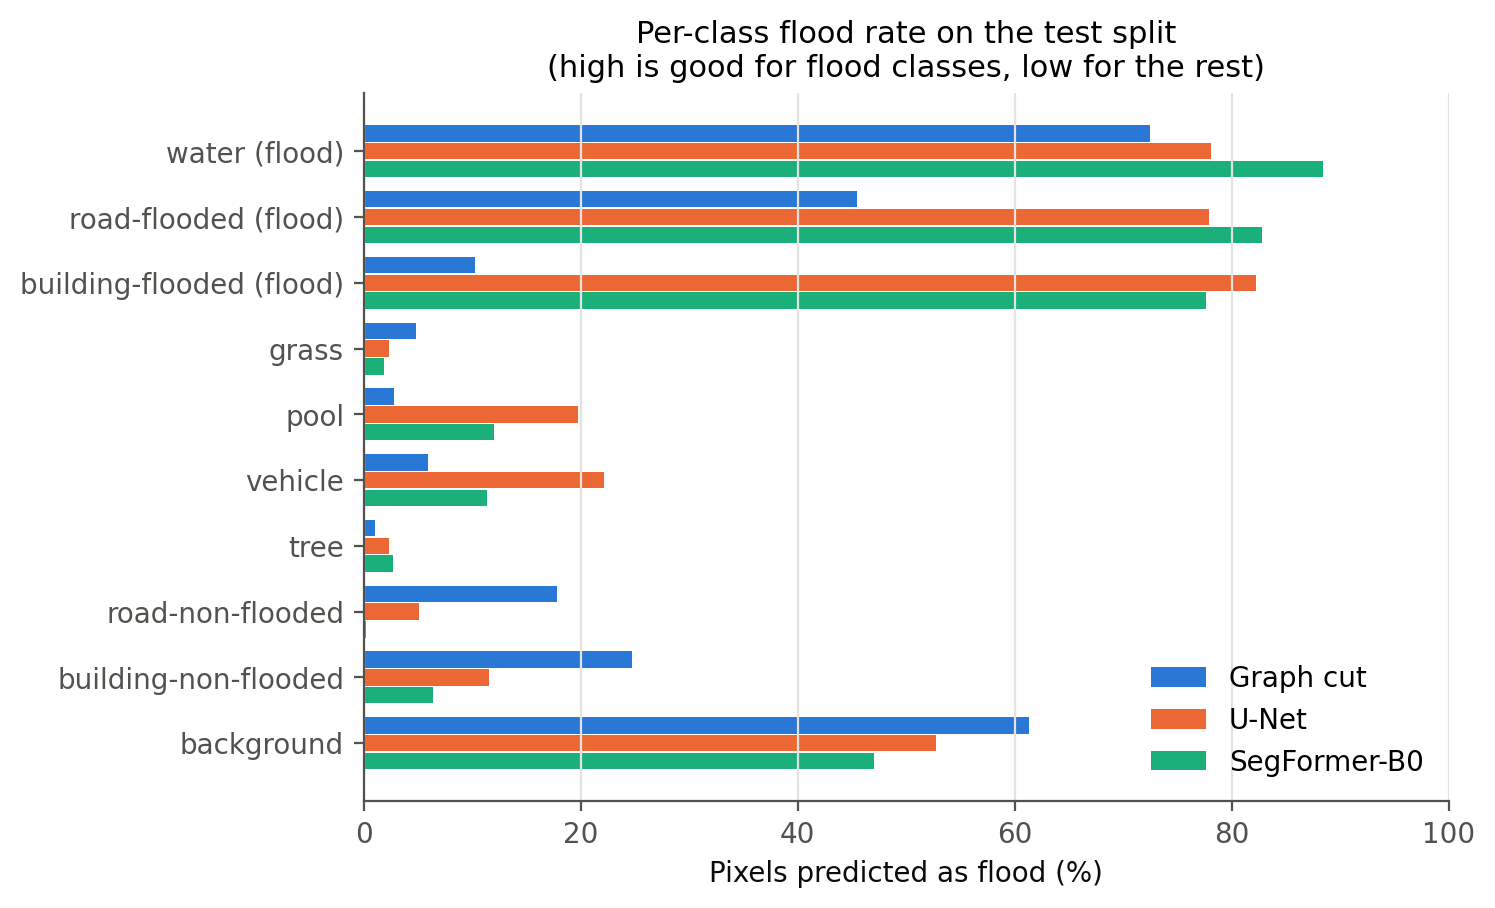

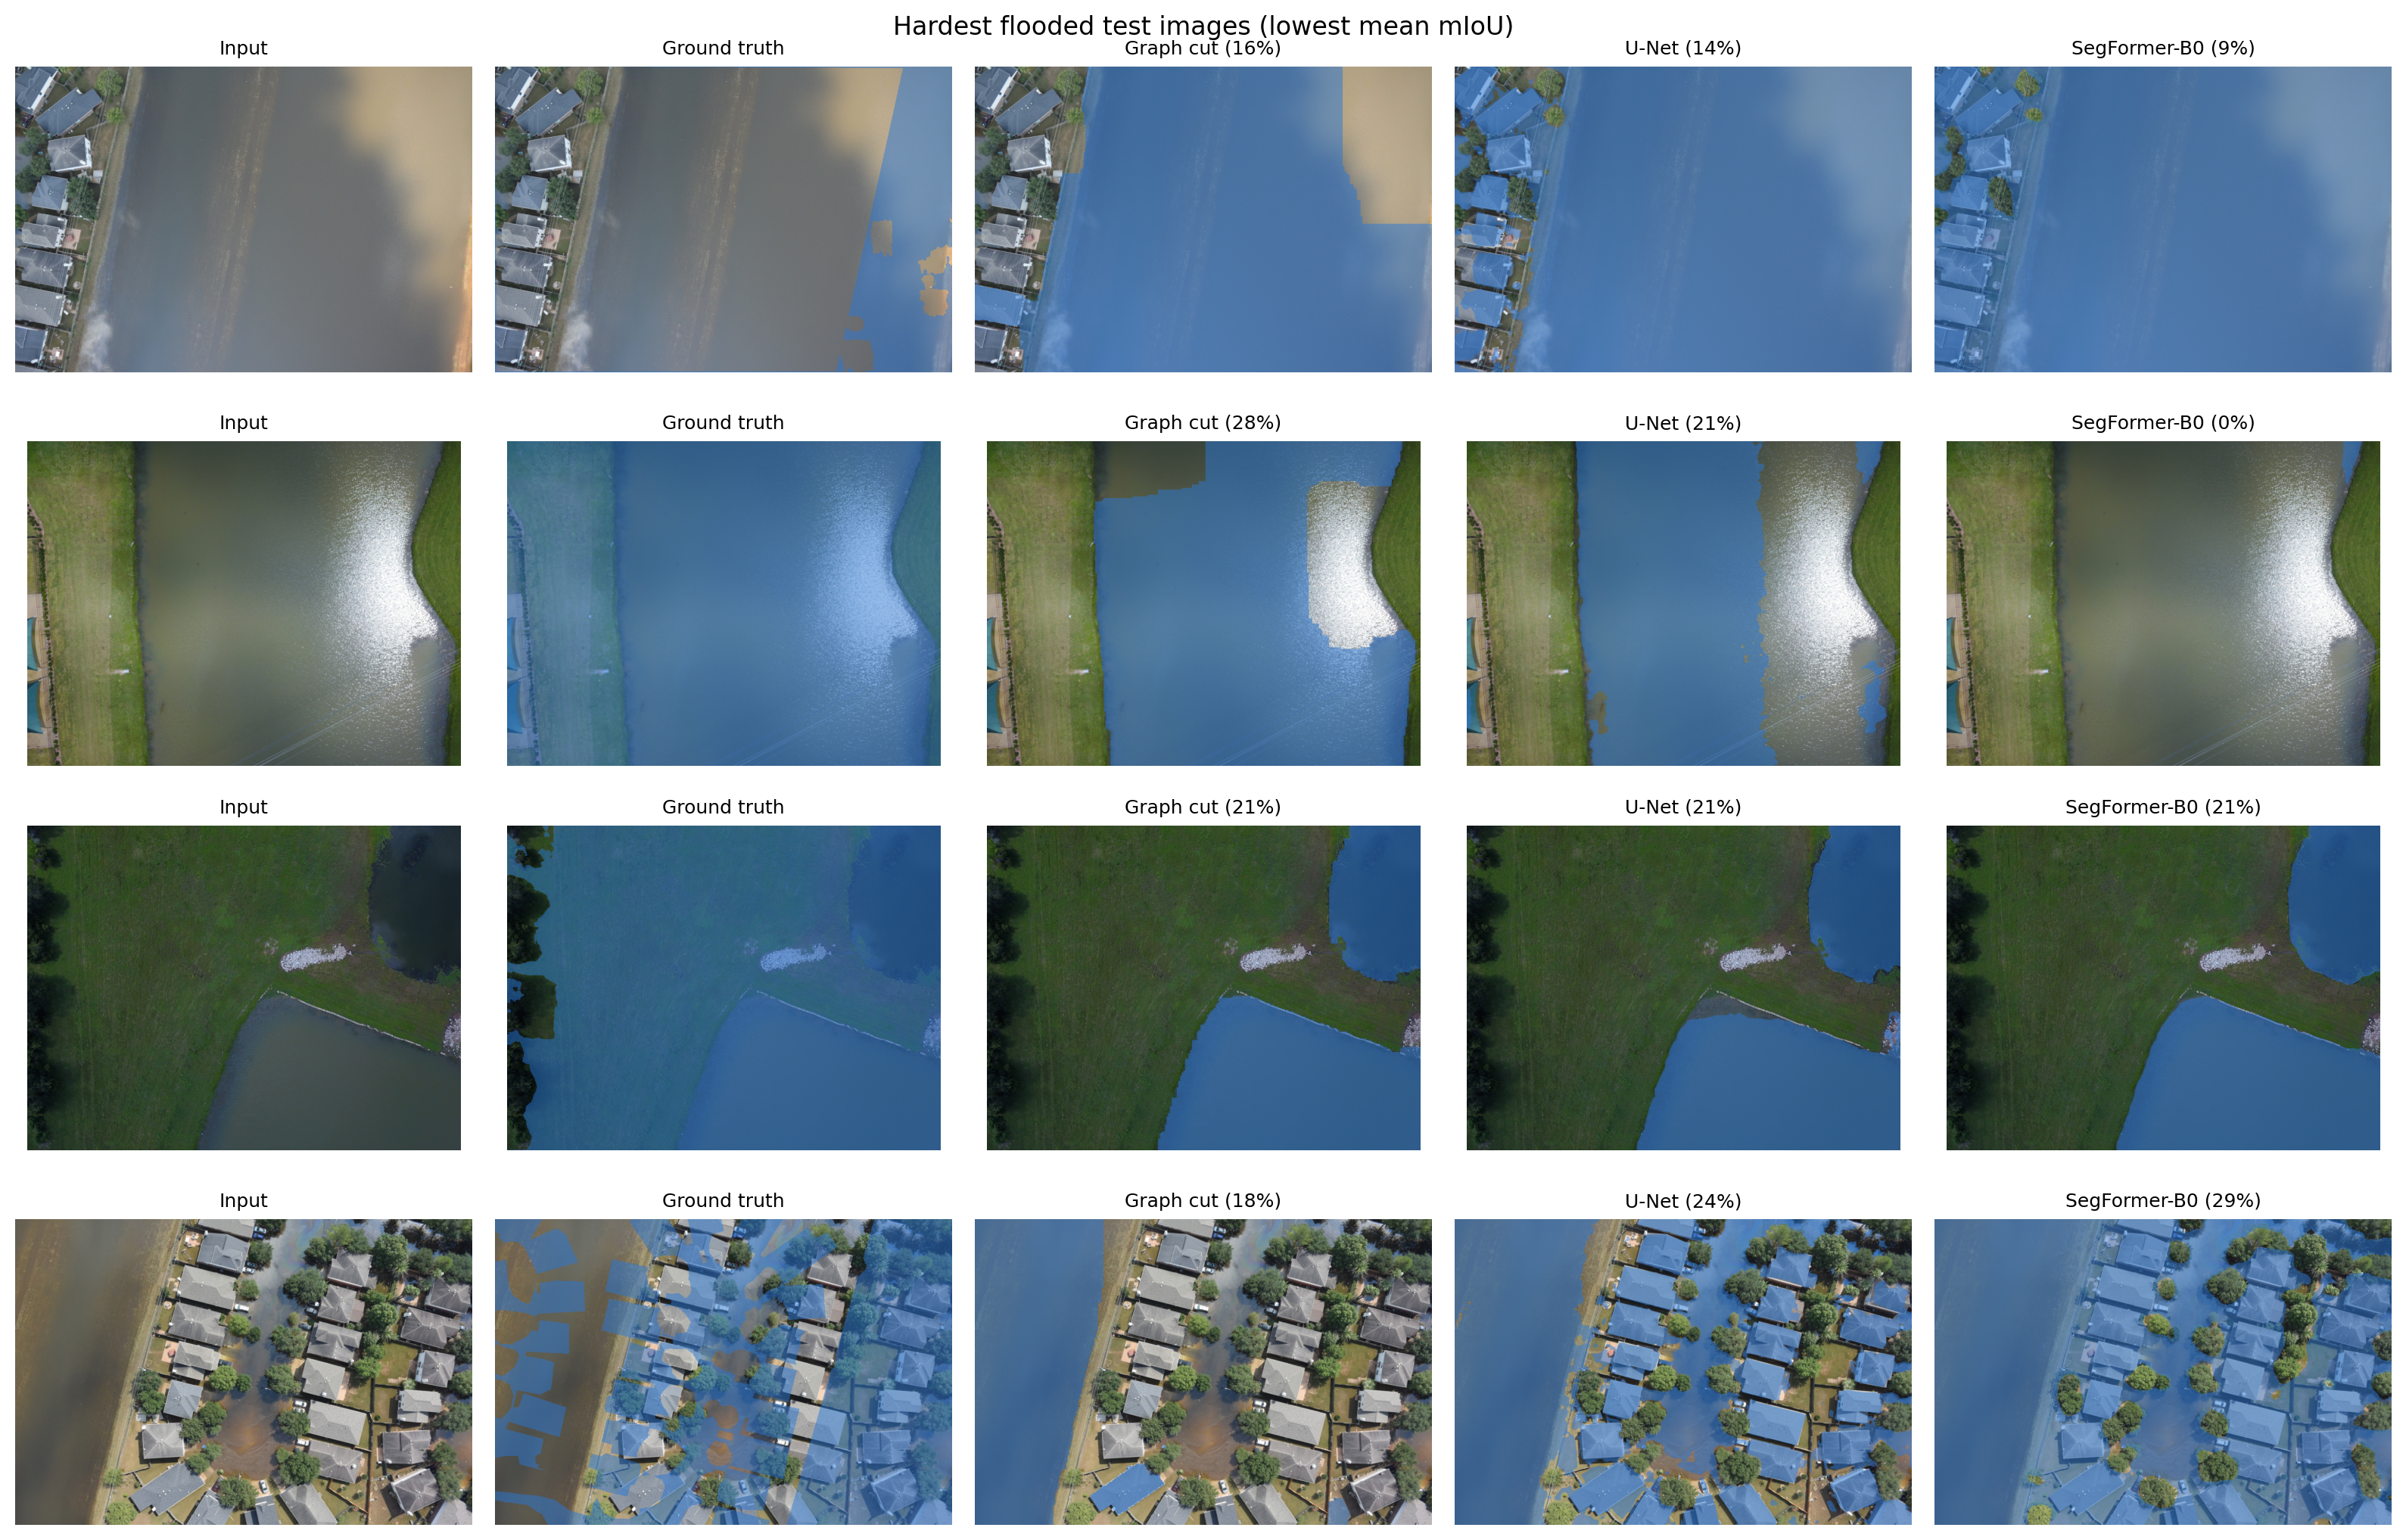

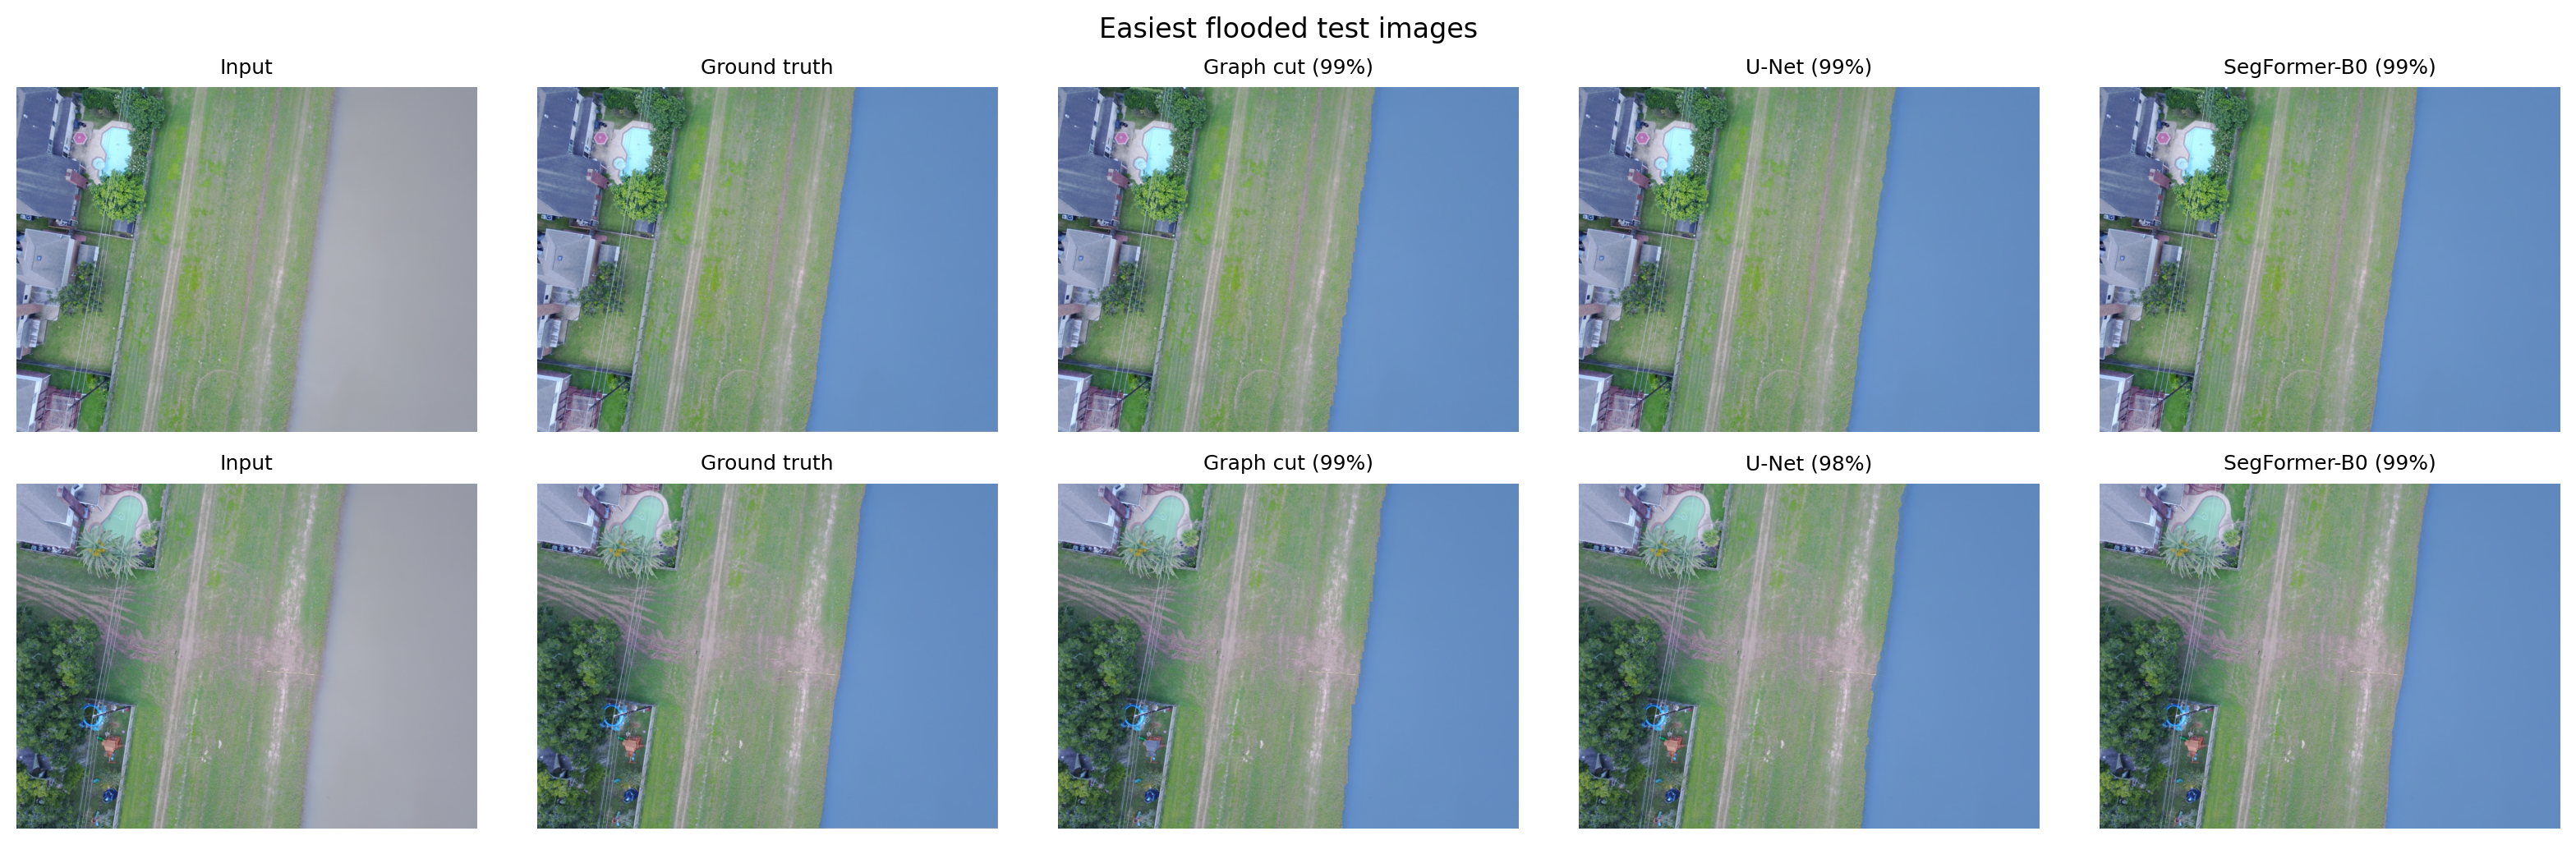

In [15]:
per_class = pd.read_csv(RESULTS_DIR / "failure_per_class.csv")
display(per_class.pivot(index="class", columns="method", values="pred_flood_pct").round(1))
display(Show(str(RESULTS_DIR / "failure_per_class.png")))
display(Show(str(RESULTS_DIR / "failure_cases.png")), Show(str(RESULTS_DIR / "qualitative_examples.png")))

## 6. Demo: all three methods on one street-level test image
The same `load`/`predict` calls the FastAPI backend uses.

In [16]:
import time

from src.methods import METHODS

image, gt = load_pair("roadway_test", read_split("roadway_test")[12])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(overlay(image, gt))
axes[0].set_title("Ground truth")
for ax, (key, info) in zip(axes[1:], METHODS.items()):
    model = info["module"].load(None, "cpu" if key == "classical" else DEVICE)
    start = time.perf_counter()
    mask = info["module"].predict(model, image)
    ax.imshow(overlay(image, mask))
    ax.set_title(f"{info['name']}: {100 * mask.mean():.0f}% flooded, {1000 * (time.perf_counter() - start):.0f} ms")
for ax in axes:
    ax.axis("off")
plt.show()

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

C:\Users\ganim\AppData\Local\Temp\ipykernel_18080\1880789411.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
